# Credit Risk Model — Notebook 3: Modeling

**Approach:**
- Tune XGBoost hyperparameters with SMOTE applied inside each CV fold
  via an imblearn Pipeline rather than before splitting in order to avoid
  synthetic points leaking across the train/validation boundary
- Train the final model on the full dataset with best params
- Evaluate on the held-out test set

**Models compared:** Logistic Regression (baseline) vs XGBoost

**Metrics:** AUC-ROC and precision/recall — NOT accuracy, because
the real test set is imbalanced and accuracy would mislead.

In [1]:
import sys
import json
import warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_score)
from sklearn.metrics import (
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, precision_score, recall_score, brier_score_loss)

from sklearn.calibration import calibration_curve
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")


def find_repo_root(marker=".git"):
    current = Path.cwd()
    for directory in [current] + list(current.parents):
        if (directory / marker).exists():
            return directory
    raise FileNotFoundError(f"No '{marker}' found above {current}")


REPO_ROOT = find_repo_root()
PROJECT   = REPO_ROOT / "Credit_Risk_Model"
DATA_PROC = PROJECT / "data" / "processed"
OUTPUTS   = PROJECT / "outputs" / "figures"
OUTPUTS.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT))

data = np.load(DATA_PROC / "model_arrays.npz")
X_train_orig = data["X_train_orig"]   # imbalanced
y_train_orig = data["y_train_orig"]
X_train_bal  = data["X_train_bal"]    # SMOTE-balanced
y_train_bal  = data["y_train_bal"]
X_test       = data["X_test_proc"]
y_test       = data["y_test"]

feature_names = np.load(DATA_PROC / "feature_names.npy", allow_pickle=True)

print(f"Imbalanced train: {X_train_orig.shape}")
print(f"SMOTE train     : {X_train_bal.shape}")
print(f"Test            : {X_test.shape}")

Imbalanced train: (1099132, 83)
SMOTE train     : (1725982, 83)
Test            : (274783, 83)


In [2]:
sns.set_style("whitegrid")

def evaluate(name, y_true, y_prob, threshold=0.5):
    """
    Return a dict of metrics AND print a short report.
    We report BOTH ROC-AUC and PR-AUC because on imbalanced credit
    data ROC-AUC is optimistic — PR-AUC reflects the real tradeoff
    between catching defaults and rejecting good applicants.
    """
    y_pred = (y_prob >= threshold).astype(int)
    roc = roc_auc_score(y_true, y_prob)
    pr  = average_precision_score(y_true, y_prob)   # PR-AUC

    print(f" threshold={threshold:.2f}")
    print(f"ROC-AUC: {roc:.4f}   PR-AUC: {pr:.4f}")
    print(classification_report(y_true, y_pred,
                                target_names=["Paid", "Default"]))
    return {"name": name, "roc_auc": roc, "pr_auc": pr,
            "y_prob": y_prob, "threshold": threshold}

In [3]:
results = []

lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_bal, y_train_bal)
results.append(evaluate("Logistic — SMOTE", y_test, lr_smote.predict_proba(X_test)[:, 1]))

lr_weighted = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
lr_weighted.fit(X_train_orig, y_train_orig)
results.append(evaluate("Logistic — Class Weights", y_test, lr_weighted.predict_proba(X_test)[:, 1]))

 threshold=0.50
ROC-AUC: 0.7067   PR-AUC: 0.3916
              precision    recall  f1-score   support

        Paid       0.87      0.63      0.73    215748
     Default       0.33      0.67      0.44     59035

    accuracy                           0.64    274783
   macro avg       0.60      0.65      0.59    274783
weighted avg       0.76      0.64      0.67    274783

 threshold=0.50
ROC-AUC: 0.7090   PR-AUC: 0.3930
              precision    recall  f1-score   support

        Paid       0.88      0.63      0.73    215748
     Default       0.33      0.67      0.44     59035

    accuracy                           0.64    274783
   macro avg       0.60      0.65      0.59    274783
weighted avg       0.76      0.64      0.67    274783



In [4]:
pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", XGBClassifier(eval_metric="auc", random_state=42, n_jobs=-1)),
])

param_dist = {
    "clf__n_estimators":     [200, 300, 400],
    "clf__max_depth":        [4, 5, 6, 8],
    "clf__learning_rate":    [0.01, 0.05, 0.1],
    "clf__subsample":        [0.7, 0.8, 1.0],
    "clf__colsample_bytree": [0.7, 0.8, 1.0],
}

search = RandomizedSearchCV(
    pipe, param_distributions=param_dist, n_iter=20, scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42, n_jobs=-1, verbose=1,
)

sample_size = min(200_000, len(X_train_orig))
rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_train_orig), size=sample_size, replace=False)

search.fit(X_train_orig[sample_idx], y_train_orig[sample_idx])  # only ONE call now

best_params = {k.split("__", 1)[1]: v for k, v in search.best_params_.items()}
print(f"Best CV AUC: {search.best_score_:.4f}")
print(f"Best params: {best_params}")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best CV AUC: 0.7160
Best params: {'subsample': 0.8, 'n_estimators': 400, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


In [5]:
xgb_smote = XGBClassifier(**best_params, eval_metric="auc", random_state=42, n_jobs=-1)
xgb_smote.fit(X_train_bal, y_train_bal)
results.append(evaluate("XGBoost — SMOTE", y_test, xgb_smote.predict_proba(X_test)[:, 1]))

spw = (y_train_orig == 0).sum() / (y_train_orig == 1).sum()
xgb_weighted = XGBClassifier(**best_params, eval_metric="auc", scale_pos_weight=spw,
                              random_state=42, n_jobs=-1)
xgb_weighted.fit(X_train_orig, y_train_orig)
results.append(evaluate("XGBoost — Class Weights", y_test, xgb_weighted.predict_proba(X_test)[:, 1]))

 threshold=0.50
ROC-AUC: 0.7203   PR-AUC: 0.4098
              precision    recall  f1-score   support

        Paid       0.80      0.97      0.88    215748
     Default       0.56      0.12      0.20     59035

    accuracy                           0.79    274783
   macro avg       0.68      0.55      0.54    274783
weighted avg       0.75      0.79      0.73    274783

 threshold=0.50
ROC-AUC: 0.7264   PR-AUC: 0.4180
              precision    recall  f1-score   support

        Paid       0.88      0.65      0.75    215748
     Default       0.35      0.68      0.46     59035

    accuracy                           0.66    274783
   macro avg       0.61      0.66      0.60    274783
weighted avg       0.77      0.66      0.69    274783



In [6]:
cv_pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", XGBClassifier(**best_params, eval_metric="aucpr", random_state=42, n_jobs=-1)),
])

cv_sample = min(150_000, len(X_train_orig))
idx = np.random.RandomState(0).choice(len(X_train_orig), cv_sample, replace=False)

cv_scores = cross_val_score(
    cv_pipe, X_train_orig[idx], y_train_orig[idx],
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="average_precision", n_jobs=-1
)
print(f"Cross-validated PR-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

Cross-validated PR-AUC: 0.3986 (+/- 0.0060)


In [7]:
comparison = pd.DataFrame([
    {"Model": r["name"], "ROC-AUC": r["roc_auc"], "PR-AUC": r["pr_auc"]}
    for r in results
]).sort_values("PR-AUC", ascending=False).reset_index(drop=True)

print("MODEL COMPARISON (sorted by PR-AUC — the metric that matters here)\n")
print(comparison.to_string(index=False))

best = max(results, key=lambda r: r["pr_auc"])
print(f"\nBest model: {best['name']} (PR-AUC={best['pr_auc']:.4f})")

MODEL COMPARISON (sorted by PR-AUC — the metric that matters here)

                   Model  ROC-AUC   PR-AUC
 XGBoost — Class Weights 0.726395 0.418025
         XGBoost — SMOTE 0.720307 0.409779
Logistic — Class Weights 0.708988 0.393038
        Logistic — SMOTE 0.706710 0.391572

Best model: XGBoost — Class Weights (PR-AUC=0.4180)


In [8]:
COST_FALSE_NEG = 15000
COST_FALSE_POS = 1500

best_prob = best["y_prob"]
thresholds = np.arange(0.05, 0.95, 0.025)

rows = []
for t in thresholds:
    pred = (best_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    expected_cost = fn * COST_FALSE_NEG + fp * COST_FALSE_POS
    rows.append({
        "threshold":     t,
        "precision":     precision_score(y_test, pred, zero_division=0),
        "recall":        recall_score(y_test, pred),
        "approval_rate": (pred == 0).mean(),
        "false_neg":     fn,
        "false_pos":     fp,
        "expected_cost": expected_cost,
    })

thresh_df = pd.DataFrame(rows)
best_row = thresh_df.loc[thresh_df["expected_cost"].idxmin()]
CHOSEN_THRESHOLD = float(best_row["threshold"])

print(f"Cost-optimal threshold: {CHOSEN_THRESHOLD:.3f}")
print(f"  Recall at this threshold   : {best_row['recall']:.1%}")
print(f"  Precision at this threshold: {best_row['precision']:.1%}")
print(f"  Approval rate              : {best_row['approval_rate']:.1%}")
print(f"  Expected cost              : ${best_row['expected_cost']:,.0f}")

Cost-optimal threshold: 0.250
  Recall at this threshold   : 95.7%
  Precision at this threshold: 24.9%
  Approval rate              : 17.3%
  Expected cost              : $294,103,500


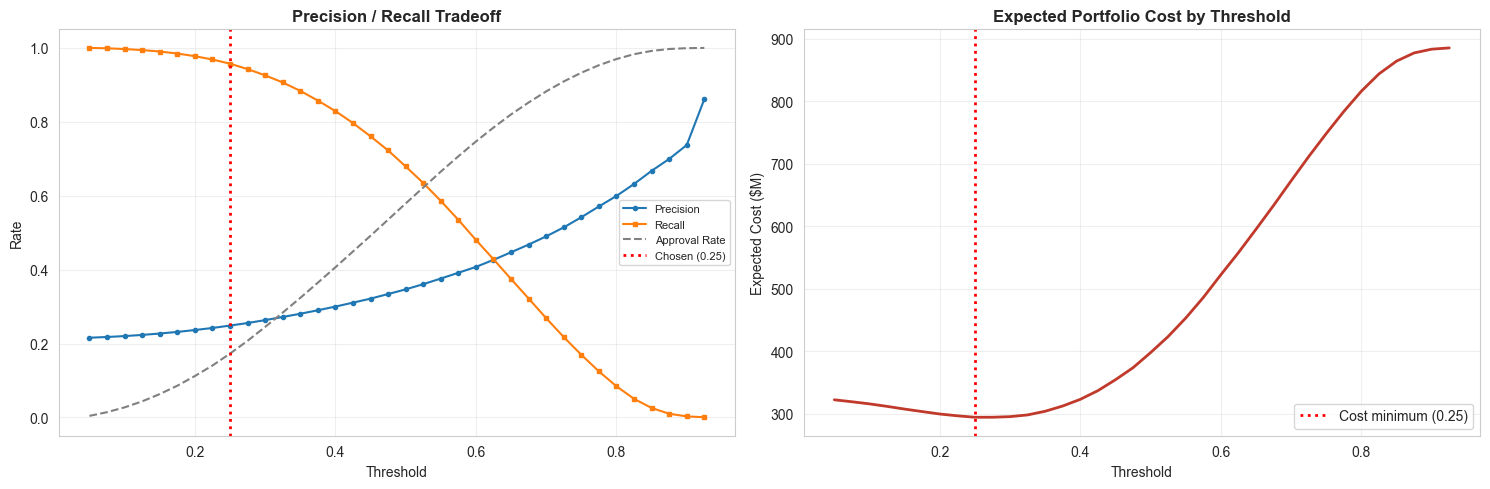

In [9]:
# Precision / Recall tradeoff with the cost-optimal point marked
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Left: precision / recall / approval vs threshold
ax1.plot(thresh_df["threshold"], thresh_df["precision"], label="Precision", marker="o", ms=3)
ax1.plot(thresh_df["threshold"], thresh_df["recall"],    label="Recall", marker="s", ms=3)
ax1.plot(thresh_df["threshold"], thresh_df["approval_rate"],
         label="Approval Rate", linestyle="--", color="gray")
ax1.axvline(CHOSEN_THRESHOLD, color="red", linestyle=":", linewidth=2,
            label=f"Chosen ({CHOSEN_THRESHOLD:.2f})")
ax1.set_xlabel("Threshold"); ax1.set_ylabel("Rate")
ax1.set_title("Precision / Recall Tradeoff", fontweight="bold")
ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3)

# Right: expected cost curve
ax2.plot(thresh_df["threshold"], thresh_df["expected_cost"] / 1e6,
         color="#c0392b", linewidth=2)
ax2.axvline(CHOSEN_THRESHOLD, color="red", linestyle=":", linewidth=2,
            label=f"Cost minimum ({CHOSEN_THRESHOLD:.2f})")
ax2.set_xlabel("Threshold"); ax2.set_ylabel("Expected Cost ($M)")
ax2.set_title("Expected Portfolio Cost by Threshold", fontweight="bold")
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUTS / "09_threshold_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

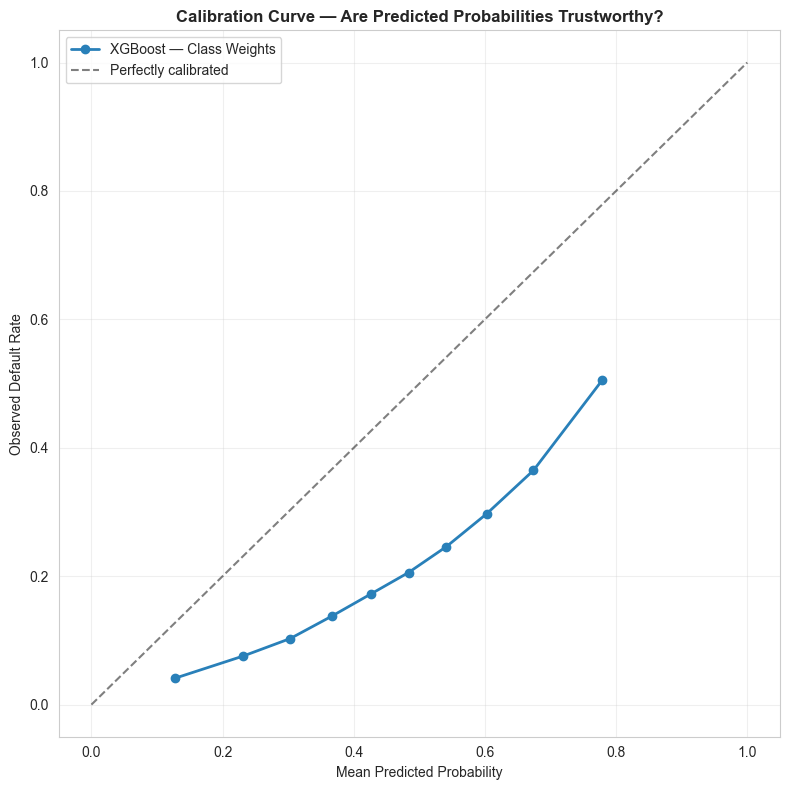

Brier score: 0.2114 (0 = perfect, lower is better)


In [10]:
# Probability calibration check
# A credit score of 0.30 should mean ~30% default risk. SMOTE distorts this, so we check calibration explicitly.

fig, ax = plt.subplots(figsize=(8, 8))

# Comparing the best model against a perfectly-calibrated diagonal
prob_true, prob_pred = calibration_curve(
    y_test, best_prob, n_bins=10, strategy="quantile"
)

ax.plot(prob_pred, prob_true, marker="o", linewidth=2,
        label=best["name"], color="#2980b9")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Perfectly calibrated")

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Default Rate")
ax.set_title("Calibration Curve — Are Predicted Probabilities Trustworthy?",
             fontweight="bold")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUTS / "10_calibration.png", dpi=150, bbox_inches="tight")
plt.show()

# Quantify miscalibration with Brier score (lower = better)
from sklearn.metrics import brier_score_loss
brier = brier_score_loss(y_test, best_prob)
print(f"Brier score: {brier:.4f} (0 = perfect, lower is better)")

In [11]:
recall_pct = best_row["recall"] * 100
approval_pct = best_row["approval_rate"] * 100
print(f"Recall: {recall_pct:.1f}%   Approval: {approval_pct:.1f}%")

Recall: 95.7%   Approval: 17.3%


### Choosing a Threshold — Business Rationale

The threshold sweep shows the tradeoff. For a lender, missing a
default (false negative) is far costlier than declining a good
applicant (false positive) — a charged-off loan loses the full
principal, while a declined good applicant is only an opportunity
cost. This asymmetry argues for a lower threshold that prioritizes
recall.

At the cost-optimal threshold of 0.250, the model flags roughly
95.7% of true defaults while approving 17.3% of applicants.
That's an aggressive decline rate driven directly by the
\$15,000/ / \$1,500/ cost assumptions below, which are illustrative
placeholders, not validated figures. A real deployment would need a
risk committee to set those costs before this threshold is trusted,
and a threshold in the 0.35–0.45 range (routing borderline cases to
manual review) is a more conservative starting point for a first-line
screen.

In [12]:
cost_at_05 = thresh_df.loc[thresh_df["threshold"].sub(0.5).abs().idxmin(), "expected_cost"]
cost_at_chosen = best_row["expected_cost"]
pct_reduction = (1 - cost_at_chosen / cost_at_05) * 100
print(f"Cost @0.5: ${cost_at_05:,.0f}   Cost @chosen: ${cost_at_chosen:,.0f}   Reduction: {pct_reduction:.1f}%")

Cost @0.5: $397,504,500   Cost @chosen: $294,103,500   Reduction: 26.0%


## Business Impact

At the cost-optimal threshold of 0.250, on a representative book
of 10,000 loans:

- The model flags 95.7% of loans that would default
- It declines 82.7% of all applicants
- Using cost assumptions of \$15,000 per missed default and \$1,500 per
  wrongly-declined good loan, expected losses fall from
  \$397,504,500/ (naive 0.5 cutoff) to \$294,103,500/ (chosen
  threshold) resulting in a 26.0% reduction.

**Recommended deployment:** use the model as a first-line screen at
this threshold, routing borderline scores (0.25–0.45) to manual
underwriter review rather than auto-decline. This captures most of
the loss-avoidance while protecting approval volume.

**Caveats:** trained on 2007–2018 Lending Club data; performance
should be re-validated on current-population data before deployment,
and the cost assumptions above should be set by the risk committee,
not the modeler.

In [13]:
model_lookup = {
    "Logistic — SMOTE": lr_smote,
    "Logistic — Class Weights": lr_weighted,
    "XGBoost — SMOTE": xgb_smote,
    "XGBoost — Class Weights": xgb_weighted,
}
best_model = model_lookup[best["name"]]

joblib.dump(best_model, DATA_PROC / "final_model.joblib")
with open(DATA_PROC / "model_config.json", "w") as f:
    json.dump({"model": best["name"],
               "threshold": CHOSEN_THRESHOLD,
               "roc_auc": best["roc_auc"],
               "pr_auc": best["pr_auc"]}, f, indent=2)

print(f"Saved {best['name']} at cost-optimal threshold {CHOSEN_THRESHOLD:.3f}")

Saved XGBoost — Class Weights at cost-optimal threshold 0.250
